## Analyze Data from Fischbach Lab 

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib import patheffects
import scipy.optimize
import scipy.stats
from scipy.optimize import minimize, LinearConstraint, Bounds, NonlinearConstraint, linprog
from sklearn.cluster import SpectralClustering, KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from math import erf
import multiprocessing as mp
# from tqdm import tqdm
from joblib import Parallel, delayed
import itertools
import os
import time
import pandas as pd
import plotly.graph_objects as go

plt.style.use('/Users/ObinnaUkogu/Desktop/custom.mplstyle')
%config InlineBackend.figure_format = 'retina'

# set colors
ito_colors = [
    '#E69F00',  # Orange
    '#56B4E9',  # Sky Blue
    '#009E73',  # Bluish Green
    '#F0E442',  # Yellow
    '#0072B2',  # Blue
    '#D55E00',  # Vermillion
    '#CC79A7',  # Reddish Purple
    '#999999'   # Grey
]
custom_cmap_discrete = ListedColormap(ito_colors)

#### Import datasets

In [2]:
# Import experimental data sets on T cell expansion
coverage_data = pd.read_csv('./data/nagashima_fig2.csv')
cross_reactivity_data = pd.read_csv('./data/nagashima_fig3.csv')
day14_abundance_data = pd.read_csv('./data/nagashima_extfig7a.csv')
amino_dropout_abundance_data = pd.read_csv('./data/cheng_tableS3.csv')
day0_abundance_data = pd.read_csv('./data/wang_tableS2_averageB6mice.csv')
feces_abundance_data = pd.read_csv('./data/wang_tableS2_fecesB6mice.csv')
strain_dropout_abundance_data = pd.read_csv('./data/wang_tableS3_cecum.csv')

# Make unique_id
coverage_data['strain_id'] = coverage_data['Strain_Name'].str.lower().str.strip().str.replace(r'\s+', ' ', regex=True)
cross_reactivity_data['strain_id'] = cross_reactivity_data['alt_Strain_Name'].str.lower().str.strip().str.replace(r'\s+', ' ', regex=True)
feces_abundance_data['strain_id'] = feces_abundance_data['alt_Strain_Name'].str.lower().str.strip().str.replace(r'\s+', ' ', regex=True)
day14_abundance_data['strain_id'] = day14_abundance_data['alt_Strain_Name'].str.lower().str.strip().str.replace(r'\s+', ' ', regex=True)
day0_abundance_data['strain_id'] = day0_abundance_data['alt_Strain_Name'].str.lower().str.strip().str.replace(r'\s+', ' ', regex=True)
amino_dropout_abundance_data['strain_id'] = amino_dropout_abundance_data['alt_Strain_Name'].str.lower().str.strip().str.replace(r'\s+', ' ', regex=True)
strain_dropout_abundance_data['strain_id'] = strain_dropout_abundance_data['alt_Strain_Name'].str.lower().str.strip().str.replace(r'\s+', ' ', regex=True)

amino_dropout_abundance_data.loc[:,'day2_log10_abundance'] = amino_dropout_abundance_data.day2_abundance
amino_dropout_abundance_data.loc[:,'day2_abundance'] = 100*10**(amino_dropout_abundance_data.day2_abundance)

# Compute mean abundance
feces_abundance_data.loc[:, 'wk1_mean_abundance'] = np.mean(feces_abundance_data[['Batch1_week1_m1','Batch1_week1_m2', 'Batch1_week1_m3', 
                                                                             'Batch1_week1_m4','Batch1_week1_m5']], axis = 1)
feces_abundance_data.loc[:, 'wk2_mean_abundance'] = np.mean(feces_abundance_data[['Batch1_week2_m1', 'Batch1_week2_m2','Batch1_week2_m3', 
                                                                             'Batch1_week2_m4', 'Batch1_week2_m5']], axis = 1)
feces_abundance_data.loc[:, 'wk3_mean_abundance'] = np.mean(feces_abundance_data[['Batch1_week3_m1', 'Batch1_week3_m2', 'Batch1_week3_m3', 
                                                                             'Batch1_week3_m4', 'Batch1_week3_m5']], axis = 1)
feces_abundance_data.loc[:, 'wk4_mean_abundance'] = np.mean(feces_abundance_data[['Batch1_week4_m1','Batch1_week4_m2', 'Batch1_week4_m3', 'Batch1_week4_m4',
                                                                             'Batch1_week4_m5', 'Batch2_week4_m1', 'Batch2_week4_m2',
                                                                             'Batch2_week4_m3', 'Batch3_week4_m1', 'Batch3_week4_m2',
                                                                             'Batch3_week4_m3', 'Batch3_week4_m4', 'Batch3_week4_m5']], axis = 1)

# Compute standard deviation of abundance
feces_abundance_data.loc[:, 'wk1_std_abundance'] = np.std(feces_abundance_data[['Batch1_week1_m1','Batch1_week1_m2', 'Batch1_week1_m3', 
                                                                             'Batch1_week1_m4','Batch1_week1_m5']], axis = 1)
feces_abundance_data.loc[:, 'wk2_std_abundance'] = np.std(feces_abundance_data[['Batch1_week2_m1', 'Batch1_week2_m2','Batch1_week2_m3', 
                                                                             'Batch1_week2_m4', 'Batch1_week2_m5']], axis = 1)
feces_abundance_data.loc[:, 'wk3_std_abundance'] = np.std(feces_abundance_data[['Batch1_week3_m1', 'Batch1_week3_m2', 'Batch1_week3_m3', 
                                                                             'Batch1_week3_m4', 'Batch1_week3_m5']], axis = 1)
feces_abundance_data.loc[:, 'wk4_std_abundance'] = np.std(feces_abundance_data[['Batch1_week4_m1','Batch1_week4_m2', 'Batch1_week4_m3', 'Batch1_week4_m4',
                                                                             'Batch1_week4_m5', 'Batch2_week4_m1', 'Batch2_week4_m2',
                                                                             'Batch2_week4_m3', 'Batch3_week4_m1', 'Batch3_week4_m2',
                                                                             'Batch3_week4_m3', 'Batch3_week4_m4', 'Batch3_week4_m5']], axis = 1)

# Merge data sets
full_data = coverage_data[['strain_id', 'Strain_Name','GF_pTreg_Average', 'hCom1d_pTreg_Average', 'GF_Th17_Average', 'hCom1d_Th17_Average', 'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']].merge(day14_abundance_data[['strain_id', 'day14_abundance']], how = 'left', on = 'strain_id', validate = 'one_to_one',
                                ).merge(feces_abundance_data.loc[feces_abundance_data.strain_id.notna(),['strain_id', 'Phyla', 'wk1_mean_abundance','wk2_mean_abundance', 'wk3_mean_abundance','wk4_mean_abundance']], how = 'left', on = 'strain_id', validate = 'one_to_one'
                                       ).merge(day0_abundance_data.loc[day0_abundance_data.strain_id.notna(),['strain_id', 'day0_abundance']], how = 'left', on = 'strain_id', validate = 'one_to_one'
                                       ).merge(amino_dropout_abundance_data.loc[amino_dropout_abundance_data.strain_id.notna(),['strain_id', 'day2_abundance']], how = 'left', on = 'strain_id', validate = 'one_to_one'
                                       )

# full_data = coverage_data.merge(day14_abundance_data[['alt_Strain_Name', 'day14_abundance']], how = 'left', left_on = 'Strain_Name', validate = 'one_to_one',
#                                 right_on = 'alt_Strain_Name').merge(amino_dropout_abundance_data.loc[amino_dropout_abundance_data.alt_Strain_Name.notna(),['alt_Strain_Name', 'day2_abundance']], how = 'left', left_on = 'alt_Strain_Name', validate = 'one_to_one',
#                                                                     right_on = 'alt_Strain_Name').merge(day0_abundance_data.loc[day0_abundance_data.alt_Strain_Name.notna(), ['alt_Strain_Name', 'day0_abundance', 'day28_abundance']], how = 'left', left_on = 'alt_Strain_Name', validate = 'one_to_one', 
#                                                                     right_on = 'alt_Strain_Name')

In [3]:
pd.set_option('display.max_rows', None)
full_data[['Strain_Name','day0_abundance', 'day2_abundance', 'day14_abundance', 'wk1_mean_abundance','wk2_mean_abundance', 'wk3_mean_abundance','wk4_mean_abundance']].sort_values(by='day2_abundance', 
                                                                          ascending= False)

,Strain_Name,day0_abundance,day2_abundance,day14_abundance,wk1_mean_abundance,wk2_mean_abundance,wk3_mean_abundance,wk4_mean_abundance
46,Lactococcus lactis subsp. lactis Il1403,0.262280,44.865809,0.000404,8.096760e-04,0.001063,0.000885,8.311862e-04
2,Clostridium sporogenes ATCC 15579,0.198913,6.038525,0.000345,3.752872e-02,0.036989,0.052410,4.581113e-02
39,Mitsuokella multacida DSM 20544,0.297253,5.441650,0.026225,0.000000e+00,0.000000,0.000000,8.863531e-02
55,Bifidobacterium breve DSM 20213,0.456085,4.835996,0.001095,6.890518e-03,0.004686,0.004529,3.753028e-03
37,Hungatella hathewayi DSM 13479,1.948922,4.145647,2.832290,1.440275e+01,12.959897,11.172383,9.233562e+00
14,Anaerostipes caccae DSM 14662,0.444987,3.763073,0.117069,1.236932e+00,1.012077,0.881696,9.510132e-01
34,Clostridium bolteae ATCC BAA-613,1.760910,2.718043,1.463020,3.357957e+00,4.857060,4.945008,5.000297e+00
69,Bacteroides ovatus ATCC 8483,3.345641,2.548961,0.383181,2.105855e+00,0.459592,3.730396,4.152725e+00
73,Bacteroides sp. 2_1_16,3.582445,2.464561,0.243670,2.608302e-02,0.016132,0.017371,7.223800e-02
68,Bacteroides sp. D2,3.080729,2.390260,0.214433,5.697603e-02,0.034969,0.037883,1.320331e-01


#### Microbial abundance data for week 0 (inoculum) to week 4 (post-inoculation)
This data comes from multiple sources

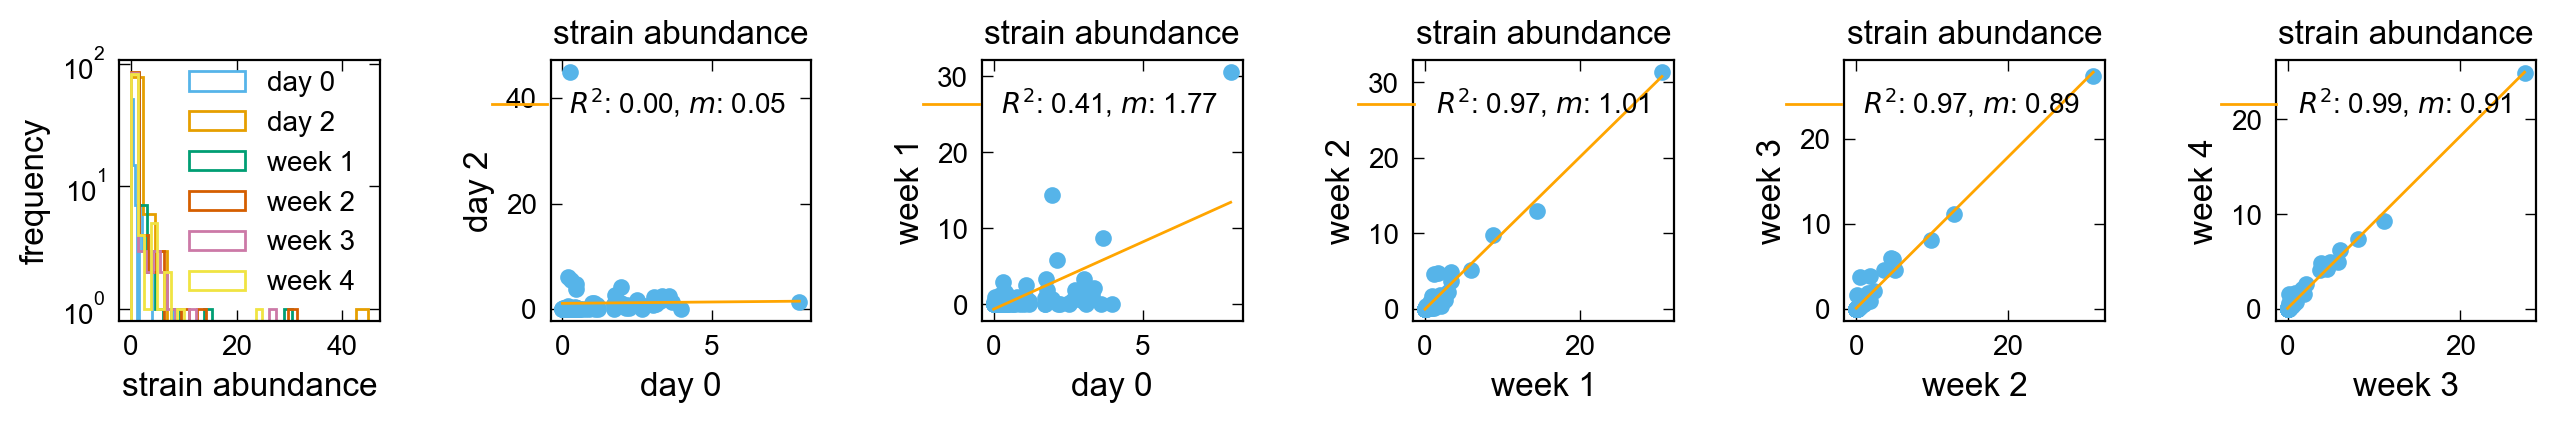

In [4]:
# Plot figures
fig, axs = plt.subplots(1, 6, figsize=(13.0, 2.0), sharex = False, constrained_layout=True)

labels = [['strain abundance', 'frequency'], 
          ['day 0', 'day 2'], ['day 0', 'week 1'], ['week 1', 'week 2'], ['week 2', 'week 3'], ['week 3', 'week 4']]
var_list = [["day0_abundance", "day2_abundance"],
            ["day0_abundance", "wk1_mean_abundance"],
            ["wk1_mean_abundance", "wk2_mean_abundance"],
            ["wk2_mean_abundance", "wk3_mean_abundance"],
            ["wk3_mean_abundance", "wk4_mean_abundance"]]

axs[0].hist(full_data.day0_abundance, bins = 20, log = True, histtype = 'step', label = 'day 0');
axs[0].hist(full_data.day2_abundance, bins = 20, log = True, histtype = 'step', label = 'day 2');
axs[0].hist(full_data.wk1_mean_abundance, bins = 20, log = True, histtype = 'step', label = 'week 1');
axs[0].hist(full_data.wk2_mean_abundance, bins = 20, log = True, histtype = 'step', label = 'week 2');
axs[0].hist(full_data.wk3_mean_abundance, bins = 20, log = True, histtype = 'step', label = 'week 3');
axs[0].hist(full_data.wk4_mean_abundance, bins = 20, log = True, histtype = 'step', label = 'week 4');

for i, u in enumerate(var_list):
    axs[i + 1].scatter(full_data[u[0]], full_data[u[1]], marker = 'o')
    mask = ~np.isnan(full_data[u[0]]) & ~np.isnan(full_data[u[1]])
    m, b, r_value, p_value, std_err = scipy.stats.linregress(full_data[u[0]][mask], full_data[u[1]][mask])
    axs[i + 1].plot(np.unique(full_data[u[0]][mask]), m*np.unique(full_data[u[0]][mask]) + b, 
                    color = 'orange', label = r'$R^2$: ' + str("{:.2f}".format(r_value**2)) + r', $m$: ' + str("{:.2f}".format(m)))

for j, ax in enumerate(axs.flat):
    ax.legend()
    if j >= 1:
        # ax.plot([0, 40], [0,40])
        # ax.semilogy()
        # ax.semilogx()
        ax.set_title('strain abundance', fontsize = 12) 
        
    ax.set_xlabel(labels[j][0], fontsize = 12)
    ax.set_ylabel(labels[j][1], fontsize = 12)
        
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

# plt.savefig('_figs/fig5_'+comment+'-perf_perturb_design'+'.pdf', format="pdf", transparent=True, dpi=300)

Day 2 data from Cheng et al (2022) is weird. There's a big change in the abundance of Lactococcus lactis subsp. lactis Il1403 from day 0 to day 2 in the data. The inoculum (day 0) does not reflect anything about the ecology of the consortium as it is made by pooling samples of each microbe grown separately in an ideal medium.

##### Microbial abundance trajectories over time: week 0 to week 4
This data is for a microbial consortium that is very similar to hCom1d. The differences are all(?) very low abundance strains.

/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/IPython/core/events.py:82: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  func(*args, **kwargs)
/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


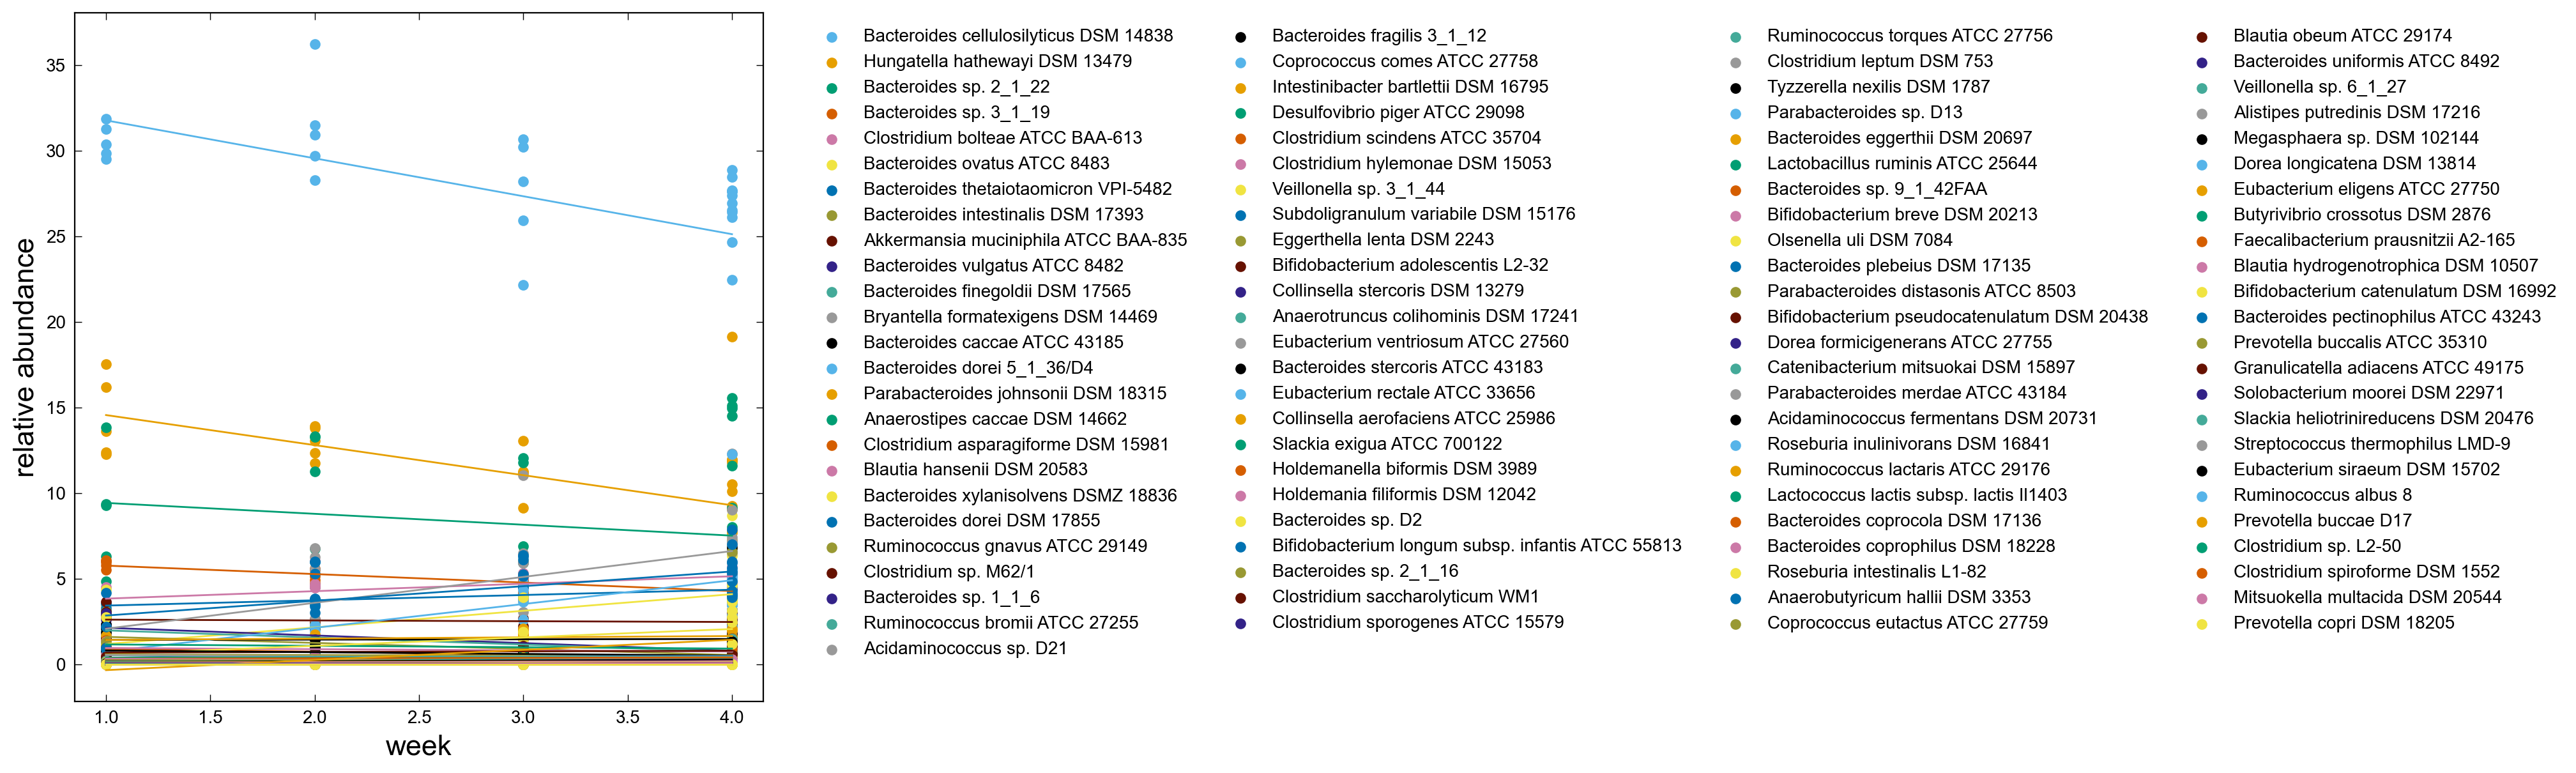

In [5]:
# Using fecal matter data from Wang et al (2023)
fig, ax = plt.subplots(1, 1, figsize=(7.0, 7.0), sharex = False, constrained_layout=True)

var_list = ['Batch1_week1_m1',
       'Batch1_week1_m2', 'Batch1_week1_m3', 'Batch1_week1_m4',
       'Batch1_week1_m5', 'Batch1_week2_m1', 'Batch1_week2_m2',
       'Batch1_week2_m3', 'Batch1_week2_m4', 'Batch1_week2_m5',
       'Batch1_week3_m1', 'Batch1_week3_m2', 'Batch1_week3_m3',
       'Batch1_week3_m4', 'Batch1_week3_m5', 'Batch1_week4_m1',
       'Batch1_week4_m2', 'Batch1_week4_m3', 'Batch1_week4_m4',
       'Batch1_week4_m5', 'Batch2_week4_m1', 'Batch2_week4_m2',
       'Batch2_week4_m3', 'Batch3_week4_m1', 'Batch3_week4_m2',
       'Batch3_week4_m3', 'Batch3_week4_m4', 'Batch3_week4_m5']

strain_list = feces_abundance_data.loc[feces_abundance_data.strain_id.notna()].sort_values(by='Batch1_week1_m1', ascending= False).alt_Strain_Name

for strain in strain_list:
    #full_data.loc[full_data.alt_Strain_Name == strain].day0_abundance.value
    y_data = feces_abundance_data.loc[feces_abundance_data.alt_Strain_Name == strain, var_list].values.ravel().tolist()
    x_data = [1, 1, 1, 1, 1, 2,2,2,2,2,3,3,3,3,3,4,4,4,4,4,4,4,4,4,4,4,4,4]
    ax.scatter(x_data, y_data, label = strain)
    m, b, r_value, p_value, std_err = scipy.stats.linregress(x_data, y_data)
    ax.plot(np.unique(x_data), 
            m*np.unique(x_data) + b)

    
ax.legend(bbox_to_anchor=(1.05, 1.0), fontsize=10, framealpha=0, ncol = 4)

ax.set_xlabel('week', fontsize = 16)
ax.set_ylabel('relative abundance', fontsize = 16)
# ax.semilogy()
ax.set_box_aspect(1)
ax.minorticks_off()
ax.tick_params(axis='both', which='major', labelsize=10)
ax.xaxis.set_tick_params(labeltop=False)

/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/IPython/core/events.py:82: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  func(*args, **kwargs)
/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


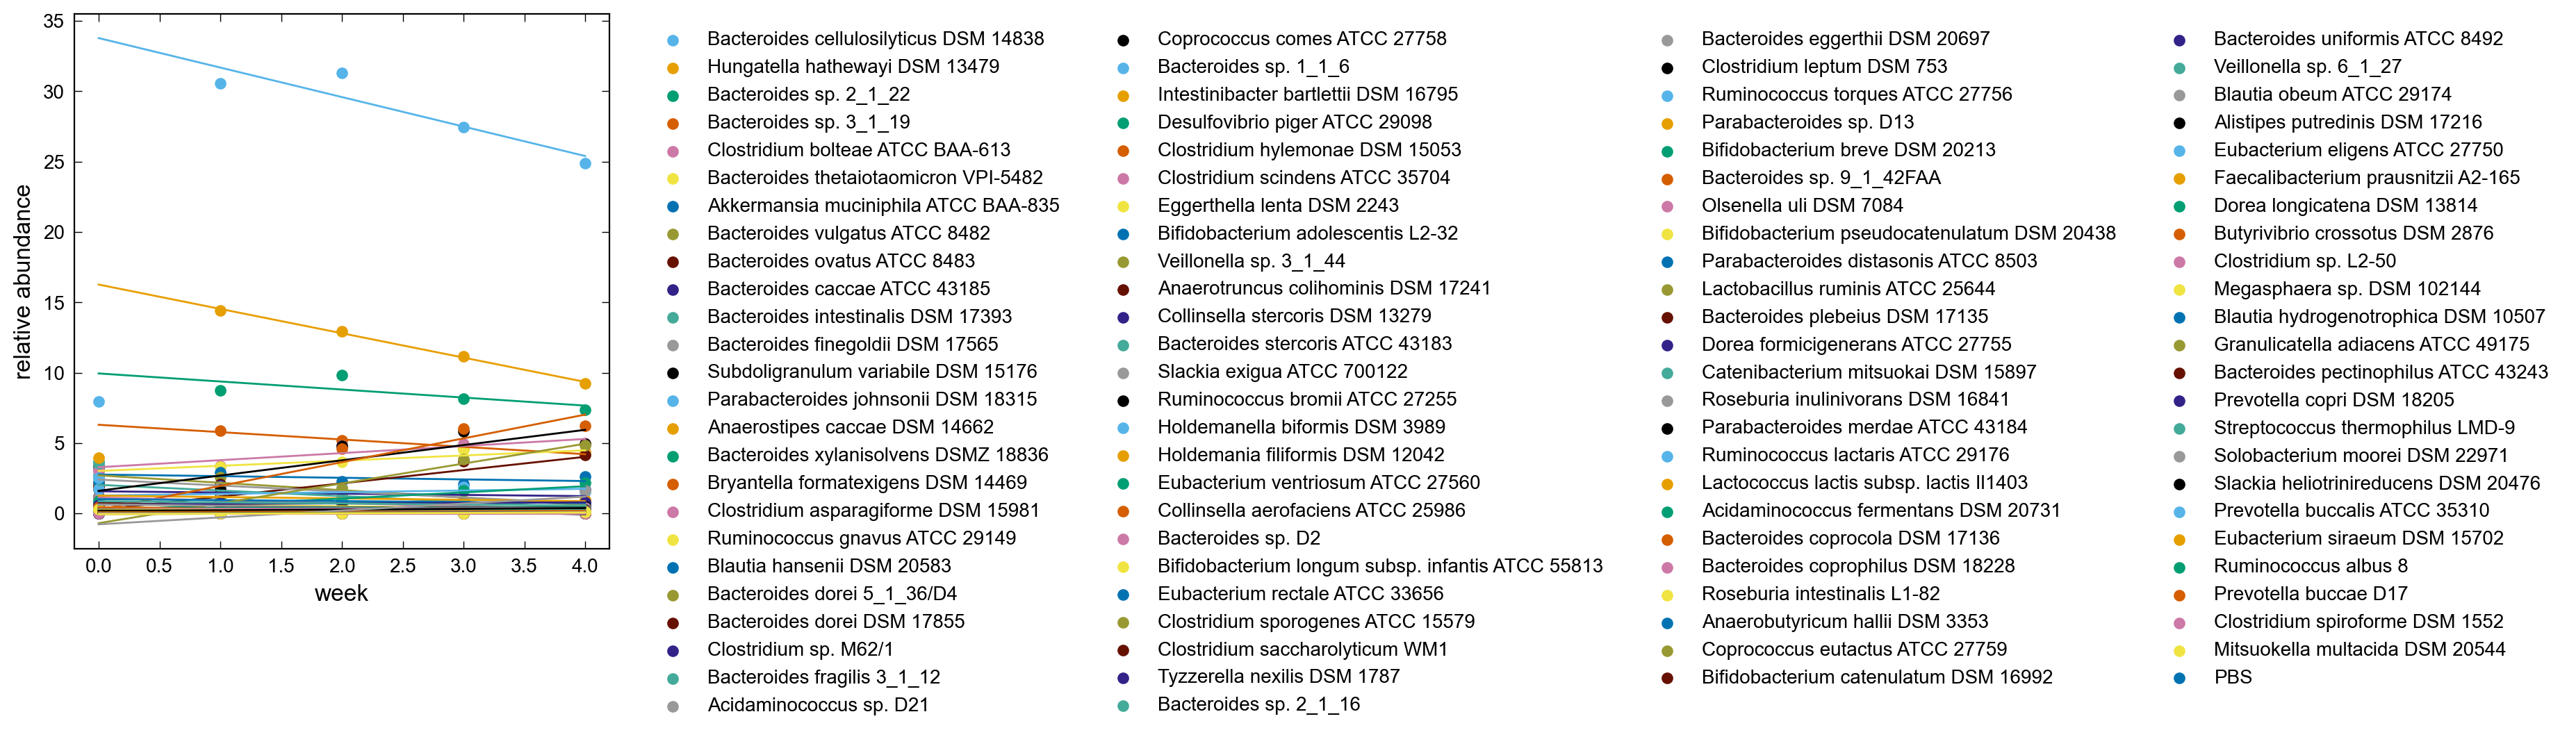

In [6]:
# Using mean data from Wang et al (2023)
fig, ax = plt.subplots(1, 1, figsize=(5.0, 5.0), sharex = False, constrained_layout=True)

var_list = ['day0_abundance', 'wk1_mean_abundance', 'wk2_mean_abundance', 'wk3_mean_abundance', 'wk4_mean_abundance']
strain_list = full_data.loc[full_data.Strain_Name.notna()].sort_values(by='wk1_mean_abundance', ascending= False).Strain_Name

for strain in strain_list:
    #full_data.loc[full_data.alt_Strain_Name == strain].day0_abundance.value
    y_data = full_data.loc[full_data.Strain_Name == strain, var_list].values.ravel().tolist()
    x_data = [0, 1, 2, 3, 4]
    ax.scatter(x_data, y_data, label = strain)
    m, b, r_value, p_value, std_err = scipy.stats.linregress(x_data[1:], y_data[1:])
    ax.plot(np.array(x_data), 
            m*np.array(x_data) + b)

    
ax.legend(bbox_to_anchor=(1.05, 1.0), fontsize=10, framealpha=0, ncol = 4)

ax.set_xlabel('week', fontsize = 12)
ax.set_ylabel('relative abundance', fontsize = 12)
# ax.semilogy()
ax.set_box_aspect(1)
ax.minorticks_off()
ax.tick_params(axis='both', which='major', labelsize=10)
ax.xaxis.set_tick_params(labeltop=False)

Fecal matter data from Wang et al. (2023) has more data points and more reliable trends. We'll use this going forward.

#### Reactivity of individual T-cell receptors to individual hCom1d microbes
This data comes from Figure 3 in Nagashima et al. (2023). Data is only available for a subset of the microbes.

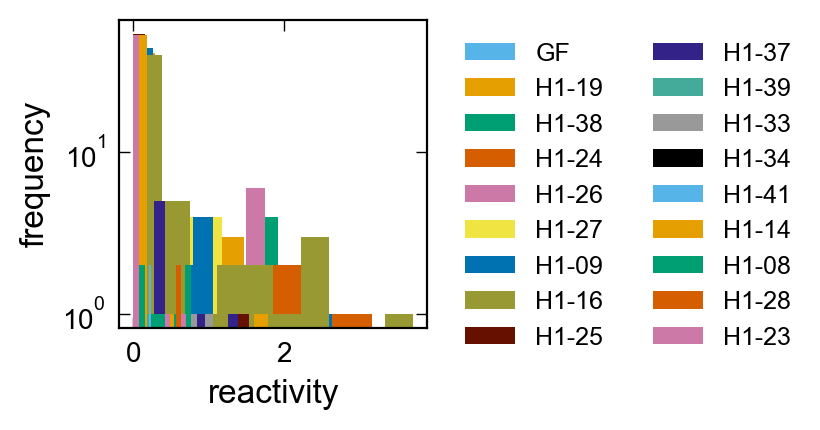

In [7]:
# Plot figures
fig, ax = plt.subplots(1, 1, figsize=(2.0, 2.0), sharex = False, constrained_layout=True)

labels = [['strain abundance', 'frequency'], 
          ['day 0', 'day 2'], ['day 0', 'day 14'], ['day 0', 'day 28'], ['day 14', 'day 28']]
var_list = ['GF',
            'H1-19','H1-38','H1-24','H1-26','H1-27','H1-09','H1-16',
            'H1-25',
            'H1-37','H1-39','H1-33','H1-34',
            'H1-41','H1-14','H1-08',
            'H1-28',
            'H1-23']

for var in var_list:
    ax.hist(pd.to_numeric(cross_reactivity_data[var]), bins = 10, log = True, label = var);

    
ax.legend(bbox_to_anchor=(1.05, 1.0), fontsize=9, framealpha=0, ncol = 2)

ax.set_xlabel('reactivity', fontsize = 12)
ax.set_ylabel('frequency', fontsize = 12)
    
ax.set_box_aspect(1)
ax.minorticks_off()
ax.tick_params(axis='both', which='major', labelsize=10)
ax.xaxis.set_tick_params(labeltop=False)

# plt.savefig('_figs/fig5_'+comment+'-perf_perturb_design'+'.pdf', format="pdf", transparent=True, dpi=300)

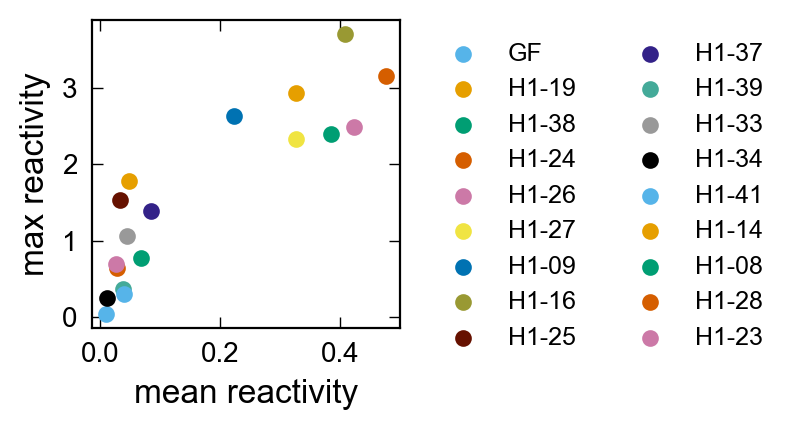

In [8]:
# Plot figures
fig, ax = plt.subplots(1, 1, figsize=(2.0, 2.0), sharex = False, constrained_layout=True)

labels = [['strain abundance', 'frequency'], 
          ['day 0', 'day 2'], ['day 0', 'day 14'], ['day 0', 'day 28'], ['day 14', 'day 28']]
var_list = ['GF',
            'H1-19','H1-38','H1-24','H1-26','H1-27','H1-09','H1-16',
            'H1-25',
            'H1-37','H1-39','H1-33','H1-34',
            'H1-41','H1-14','H1-08',
            'H1-28',
            'H1-23']

for var in var_list:
    ax.scatter(np.mean(pd.to_numeric(cross_reactivity_data[var])), np.max(pd.to_numeric(cross_reactivity_data[var])), label = var);

    
ax.legend(bbox_to_anchor=(1.05, 1.0), fontsize=9, framealpha=0, ncol = 2)

ax.set_xlabel('mean reactivity', fontsize = 12)
ax.set_ylabel('max reactivity', fontsize = 12)
    
ax.set_box_aspect(1)
ax.minorticks_off()
ax.tick_params(axis='both', which='major', labelsize=10)
ax.xaxis.set_tick_params(labeltop=False)

# plt.savefig('_figs/fig5_'+comment+'-perf_perturb_design'+'.pdf', format="pdf", transparent=True, dpi=300)

#### Immune coverage of hCom1d by T-cell repertoire
This data comes from Figure 2 in Nagashima et al. (2023).

In [9]:
# idea: highlight the relative abundance of the microbes. Signal might be clearer for more abundant microbes

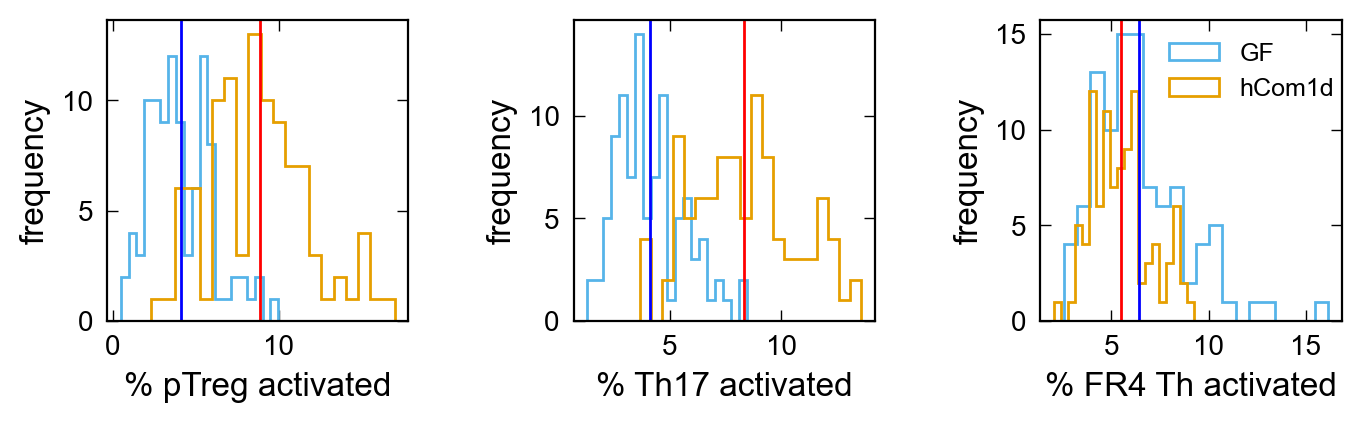

In [10]:
# Plot figures
fig, axs = plt.subplots(1, 3, figsize=(7.0, 2.0), sharex = False, constrained_layout=True)

# labels = 
var_list = [['GF_pTreg_Average', 'hCom1d_pTreg_Average'], 
                      ['GF_Th17_Average', 'hCom1d_Th17_Average'], 
                      ['GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']]

for i, var in enumerate(var_list):
    axs[i].hist(full_data[var[0]], bins = 20, histtype = 'step',label = 'GF');
    axs[i].hist(full_data[var[1]], bins = 20, histtype = 'step',label = 'hCom1d');
    axs[i].axvline(x = np.mean(full_data[var[0]]), color = 'blue')
    axs[i].axvline(x = np.mean(full_data[var[1]]), color = 'red')

    if i == (len(var_list) - 1):
        axs[i].legend(bbox_to_anchor=(1.05, 1.0), fontsize=9, framealpha=0)
    
    axs[i].set_xlabel(['% pTreg activated', '% Th17 activated', '% FR4 Th activated'][i], fontsize = 12)
    axs[i].set_ylabel('frequency', fontsize = 12)
        
    axs[i].set_box_aspect(1)
    axs[i].minorticks_off()
    axs[i].tick_params(axis='both', which='major', labelsize=10)
    axs[i].xaxis.set_tick_params(labeltop=False)

# plt.savefig('_figs/fig5_'+comment+'-perf_perturb_design'+'.pdf', format="pdf", transparent=True, dpi=300)

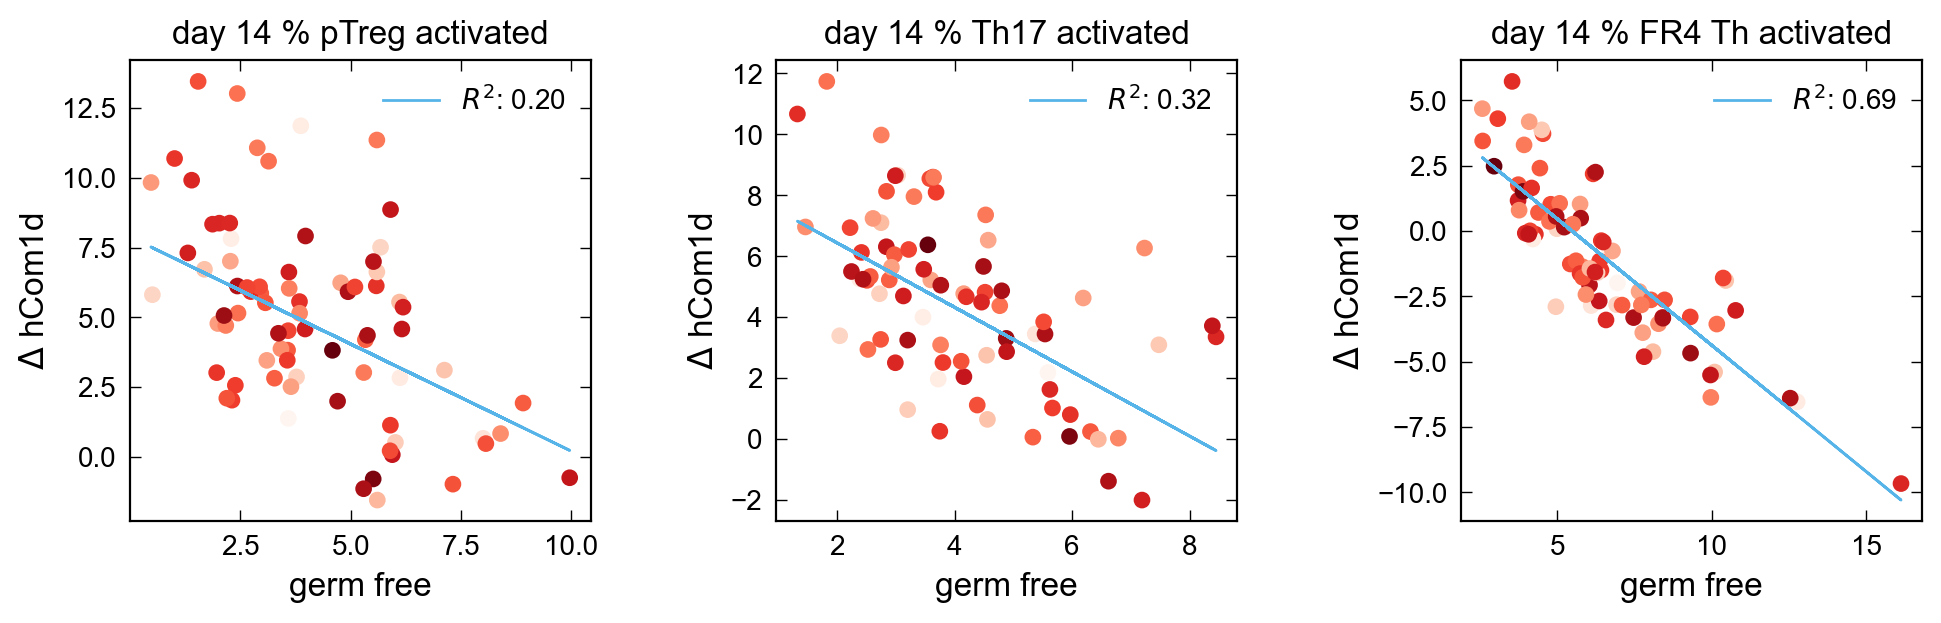

In [11]:
# Plot figures
coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
                      'GF_Th17_Average', 'hCom1d_Th17_Average', 
                      'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']

fig, axs = plt.subplots(1, 3, figsize=(10.0, 3.0), sharex = False, constrained_layout=True)

for i, ax in enumerate(axs):

    ax.scatter(full_data[coverage_variables[2*i]], 
               full_data[coverage_variables[2*i + 1]] - full_data[coverage_variables[2*i]],
                c = full_data['day14_abundance'],
               cmap = 'Reds', norm = mpl.colors.LogNorm())
    #ax.plot([0, 15], [0,15])

    m, b, r_value, p_value, std_err = scipy.stats.linregress(full_data[coverage_variables[2*i]], full_data[coverage_variables[2*i + 1]] - full_data[coverage_variables[2*i]])
    ax.plot(full_data[coverage_variables[2*i]], 
            m*full_data[coverage_variables[2*i]] + b, label = r'$R^2$: ' + str("{:.2f}".format(r_value**2)))
    
for j, ax in enumerate(axs.flat):
    ax.legend()
    # ax.semilogx()
    # ax.semilogy()
    ax.set_xlabel('germ free', fontsize = 12)
    ax.set_ylabel(r'$\Delta$ hCom1d', fontsize = 12)
    ax.set_title('day 14 '+['% pTreg activated', '% Th17 activated', '% FR4 Th activated'][j], fontsize = 12)   
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

# plt.savefig('_figs/fig5_'+comment+'-perf_perturb_design'+'.pdf', format="pdf", transparent=True, dpi=300)

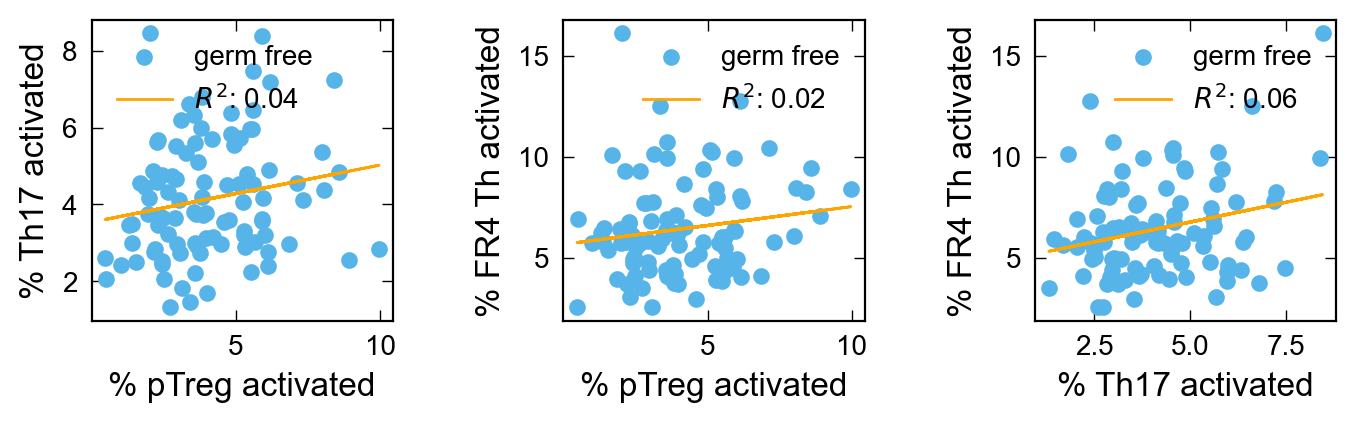

In [12]:
# Plot figures
coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
                      'GF_Th17_Average', 'hCom1d_Th17_Average', 
                      'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']
labels = [['% pTreg activated', '% Th17 activated'], ['% pTreg activated', '% FR4 Th activated'], ['% Th17 activated', '% FR4 Th activated']]
var_list = [[coverage_variables[0], coverage_variables[2]],
            [coverage_variables[0], coverage_variables[4]],
            [coverage_variables[2], coverage_variables[4]]]

fig, axs = plt.subplots(1, 3, figsize=(7.0, 2.0), sharex = False, constrained_layout=True)

axs[0].scatter(full_data[coverage_variables[0]], full_data[coverage_variables[2]], marker = 'o', label = 'germ free')
axs[1].scatter(full_data[coverage_variables[0]], full_data[coverage_variables[4]], marker = 'o', label = 'germ free')
axs[2].scatter(full_data[coverage_variables[2]], full_data[coverage_variables[4]], marker = 'o', label = 'germ free')

for i, u in enumerate(var_list):
    m, b, r_value, p_value, std_err = scipy.stats.linregress(full_data[u[0]], full_data[u[1]])
    axs[i].plot(full_data[u[0]], m*full_data[u[0]] + b, color = 'orange', label = r'$R^2$: ' + str("{:.2f}".format(r_value**2)))

for j, ax in enumerate(axs.flat):
    ax.legend()
    # ax.plot([0, 15], [0,15])
    # ax.semilogx()
    # ax.semilogy()
    ax.set_xlabel(labels[j][0], fontsize = 12)
    ax.set_ylabel(labels[j][1], fontsize = 12)
    # ax.set_title(, fontsize = 12)   
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

# plt.savefig('_figs/fig5_'+comment+'-perf_perturb_design'+'.pdf', format="pdf", transparent=True, dpi=300)

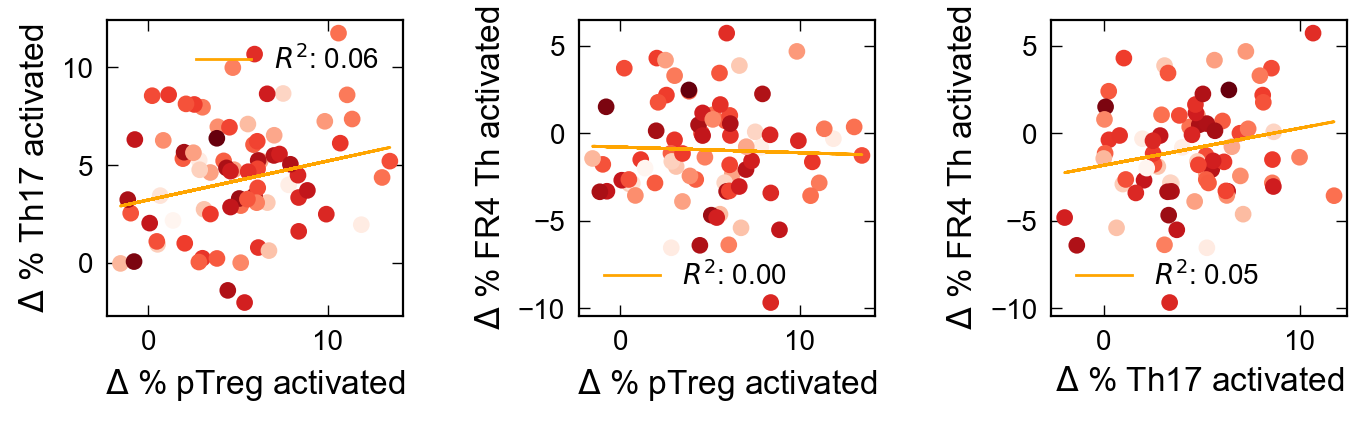

In [13]:
# Plot figures
coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
                      'GF_Th17_Average', 'hCom1d_Th17_Average', 
                      'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']
labels = [['% pTreg activated', '% Th17 activated'], ['% pTreg activated', '% FR4 Th activated'], ['% Th17 activated', '% FR4 Th activated']]
var_list = [[1, 3],
            [1, 5],
            [3, 5]]

fig, axs = plt.subplots(1, 3, figsize=(7.0, 2.0), sharex = False, constrained_layout=True)

# axs[0].scatter(full_data[coverage_variables[1]] - full_data[coverage_variables[0]], full_data[coverage_variables[3]] - full_data[coverage_variables[2]], marker = 's', label = 'hCom1d')
# axs[1].scatter(full_data[coverage_variables[1]] - full_data[coverage_variables[0]], full_data[coverage_variables[5]] - full_data[coverage_variables[4]], marker = 's', label = 'hCom1d')
# axs[2].scatter(full_data[coverage_variables[3]] - full_data[coverage_variables[2]], full_data[coverage_variables[5]] - full_data[coverage_variables[4]], marker = 's', label = 'hCom1d')

for i, u in enumerate(var_list):
    x_data = full_data[coverage_variables[u[0]]] - full_data[coverage_variables[u[0] - 1]]
    y_data = full_data[coverage_variables[u[1]]] - full_data[coverage_variables[u[1] - 1]]
    axs[i].scatter(x_data, y_data, marker = 'o', c = full_data['day14_abundance'],
               cmap = 'Reds', norm = mpl.colors.LogNorm())
    m, b, r_value, p_value, std_err = scipy.stats.linregress(x_data, y_data)
    axs[i].plot(x_data, m*x_data + b, color = 'orange', label = r'$R^2$: ' + str("{:.2f}".format(r_value**2)))

for j, ax in enumerate(axs.flat):
    ax.legend()
    ax.set_xlabel(r'$\Delta$ ' + labels[j][0], fontsize = 12)
    ax.set_ylabel(r'$\Delta$ ' + labels[j][1], fontsize = 12)
    # ax.set_title(, fontsize = 12)   
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

# plt.savefig('_figs/fig5_'+comment+'-perf_perturb_design'+'.pdf', format="pdf", transparent=True, dpi=300)

What if we do these regressions only on the most abundant microbes? Or stratified by abundance level

#### Is there a relationship between microbe abundance and immune coverage?

/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


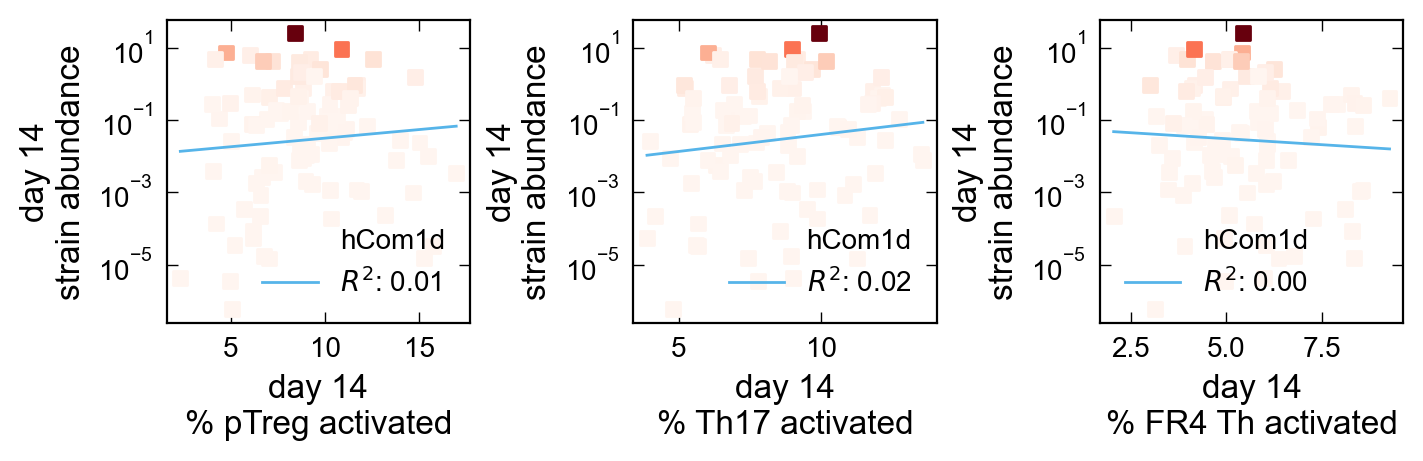

In [14]:
# Plot figures
coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
                      'GF_Th17_Average', 'hCom1d_Th17_Average', 
                      'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']

var_list = [coverage_variables[1], coverage_variables[3], coverage_variables[5]]

fig, axs = plt.subplots(1, 3, figsize=(7.0, 2.5), sharex = False, constrained_layout=True)

for i, ax in enumerate(axs):
    x_data = full_data[coverage_variables[2*i + 1]]
    y_data = full_data['wk4_mean_abundance']
    ax.scatter(x_data, 
               y_data, 
               c = full_data['wk1_mean_abundance'],
               cmap = 'Reds',
               marker = 's', label = 'hCom1d')
    mask = ~np.isnan(x_data) & ~np.isnan(y_data) & ~np.isinf(np.log10(y_data))
    m, b, r_value, p_value, std_err = scipy.stats.linregress(x_data[mask], np.log10(y_data[mask]))
    # ax.scatter(x_data[mask], m*x_data[mask] + b)
    ax.plot(np.unique(x_data[mask]), 10**(m*np.unique(x_data[mask]) + b), label = r'$R^2$: ' + str("{:.2f}".format(r_value**2)))

for j, ax in enumerate(axs.flat):
    ax.legend()
    ax.semilogy()
    ax.set_ylabel('day 14\nstrain abundance', fontsize = 12)
    ax.set_xlabel('day 14\n'+['% pTreg activated', '% Th17 activated', '% FR4 Th activated'][j], fontsize = 12)
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

# plt.savefig('_figs/fig5_'+comment+'-perf_perturb_design'+'.pdf', format="pdf", transparent=True, dpi=300)

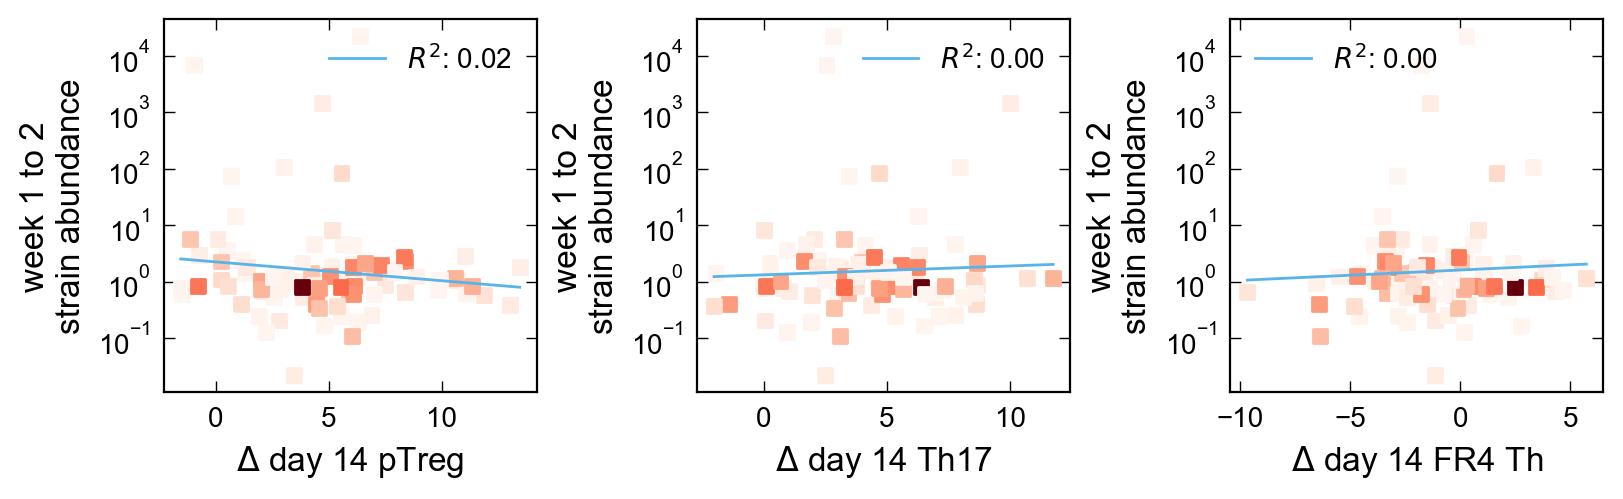

In [15]:
# Plot figures
coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
                      'GF_Th17_Average', 'hCom1d_Th17_Average', 
                      'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']

fig, axs = plt.subplots(1, 3, figsize=(8.0, 2.5), sharex = False, constrained_layout=True)

for i, ax in enumerate(axs):
    x_data = full_data[coverage_variables[2*i + 1]] - full_data[coverage_variables[2*i]]
    y_data = full_data['wk4_mean_abundance']/full_data['wk1_mean_abundance']
    ax.scatter(x_data, 
               y_data, 
               c = full_data['day0_abundance'],
               cmap = 'Reds',
               marker = 's')

    mask = ~np.isnan(x_data) & ~np.isnan(y_data) & ~np.isinf(np.log10(y_data))
    m, b, r_value, p_value, std_err = scipy.stats.linregress(x_data[mask], np.log10(y_data[mask]))
    # ax.scatter(x_data[mask], m*x_data[mask] + b)
    ax.plot(np.unique(x_data[mask]), 10**(m*np.unique(x_data[mask]) + b), label = r'$R^2$: ' + str("{:.2f}".format(r_value**2)))

for j, ax in enumerate(axs.flat):
    ax.legend()
    ax.semilogy()
    # ax.semilogx()
    ax.set_ylabel('week 1 to 2\nstrain abundance', fontsize = 12)
    ax.set_xlabel(r'$\Delta$ day 14 '+['pTreg', 'Th17', 'FR4 Th'][j], fontsize = 12)
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

# plt.savefig('_figs/fig5_'+comment+'-perf_perturb_design'+'.pdf', format="pdf", transparent=True, dpi=300)

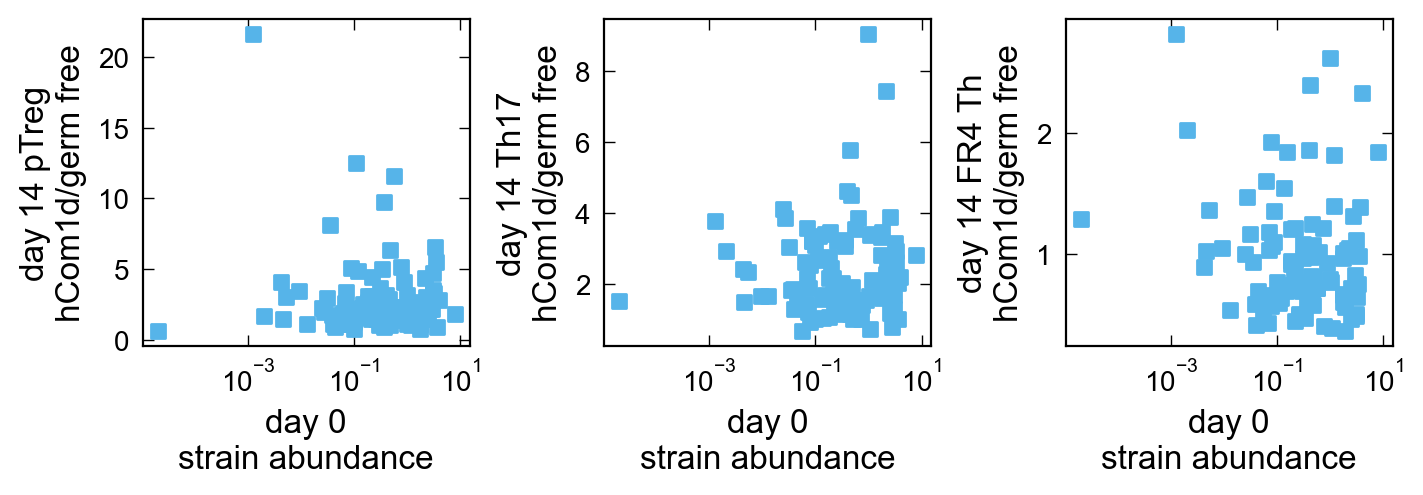

In [16]:
# Plot figures
coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
                      'GF_Th17_Average', 'hCom1d_Th17_Average', 
                      'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']

fig, axs = plt.subplots(1, 3, figsize=(7.0, 2.5), sharex = False, constrained_layout=True)

for i, ax in enumerate(axs):
    ax.scatter(full_data['day0_abundance'], 
               full_data[coverage_variables[2*i + 1]]/full_data[coverage_variables[2*i]], marker = 's')

for j, ax in enumerate(axs.flat):
    ax.semilogx()
    ax.set_xlabel('day 0\nstrain abundance', fontsize = 12)
    ax.set_ylabel('day 14 '+['pTreg\nhCom1d/germ free', 'Th17\nhCom1d/germ free', 'FR4 Th\nhCom1d/germ free'][j], fontsize = 12)
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

# plt.savefig('_figs/fig5_'+comment+'-perf_perturb_design'+'.pdf', format="pdf", transparent=True, dpi=300)

In [17]:
# # Build zehn dataset

# # Plot figures
# coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
#                       'GF_Th17_Average', 'hCom1d_Th17_Average', 
#                       'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']

# fig, axs = plt.subplots(1, 3, figsize=(7.0, 2.0), sharex = False, constrained_layout=True)

# for i, ax in enumerate(axs):

#     ax.scatter(full_data['day28_abundance'], full_data[coverage_variables[2*i]], marker = 'o', label = 'germ free')
#     ax.scatter(full_data['day28_abundance'], full_data[coverage_variables[2*i + 1]], marker = 's', label = 'hCom1d')
    

# for j, ax in enumerate(axs.flat):
#     ax.legend()
#     ax.semilogx()
#     ax.semilogy()
#     ax.set_xlabel('strain abundance', fontsize = 12)
#     ax.set_ylabel('day 28\n'+['% pTreg activated', '% Th17 activated', '% FR4 Th activated'][j], fontsize = 12)
#     ax.set_box_aspect(1)
#     ax.minorticks_off()
#     ax.tick_params(axis='both', which='major', labelsize=10)
#     ax.xaxis.set_tick_params(labeltop=False)

# # plt.savefig('_figs/fig5_'+comment+'-perf_perturb_design'+'.pdf', format="pdf", transparent=True, dpi=300)

In [18]:
# Compare compositional variance of individual microbes and microbes targeted by the same receptors.
# Hypothesis is that collective abundance of targeted microbes should vary much less than individual abundance
# Contrast this with grouping by Phylum (or other genetic data) and random shuffling
# How can I measure this? Do I have the data?

#### Ecologicy of the microbial community
Using amino acid dropouts (Cheng et al. (2022)) and strain drop outs (Wang et al. (2023).

/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/pandas/core/internals/blocks.py:393: RuntimeWarning: divide by zero encountered in log10
  result = func(self.values, **kwargs)


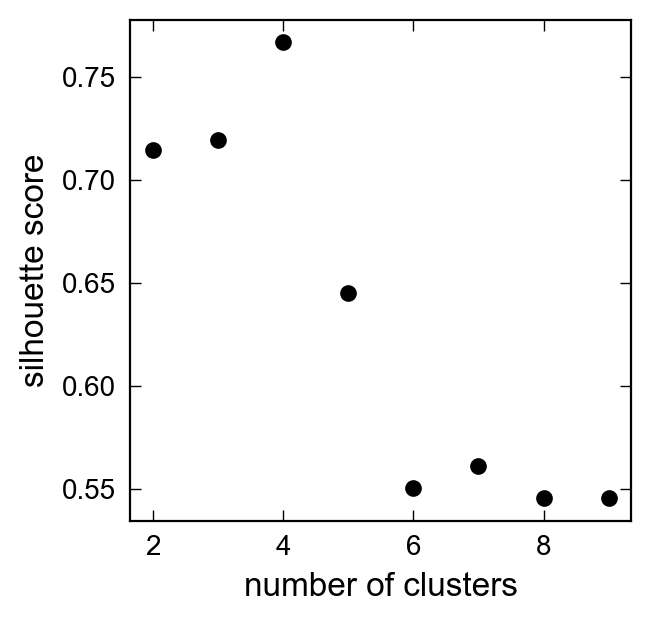

In [19]:
# Set number of clusters
fig, axs = plt.subplots(1,1, figsize=(4, 3.0), sharex='row', sharey=False,layout='constrained')

# Scale and center data for clustering
cluster_vars = ['drop_Ch_abundance','drop_Cs_abundance']

cluster_input = strain_dropout_abundance_data[cluster_vars].div(strain_dropout_abundance_data['week3_cecum_abundance'], axis=0)
mask = ~np.isnan(cluster_input) & ~np.isinf(np.log10(cluster_input))
scaler = RobustScaler()
scaler.fit(np.log10(cluster_input[cluster_vars].values[np.sum(mask, axis = 1) == len(cluster_vars)]))
for_clustering = scaler.transform(np.log10(cluster_input[cluster_vars].values[np.sum(mask, axis = 1) == len(cluster_vars)]))

# compute scores
for k in np.arange(2,10):
    clustering_object = KMeans(n_clusters=k, n_init = 10, random_state=0)
    score = silhouette_score(for_clustering, clustering_object.fit_predict(for_clustering))
    axs.scatter(k,score, color = 'black')

axs.set_xlabel('number of clusters', fontsize = 12)
axs.set_ylabel('silhouette score', fontsize = 12)
axs.set_box_aspect(1)
axs.minorticks_off()
axs.tick_params(axis='both', which='major', labelsize=10)

#plt.savefig('_figs/figSI_'+comment+'-cluster_silhouette_scores'+'.pdf', format="pdf", transparent=True, dpi=300)

[0.45930301 0.15991311 0.12125397 0.0691664  0.05216496 0.04733016
 0.0307766  0.02321563 0.01692498 0.0097928  0.00720319 0.00295521]


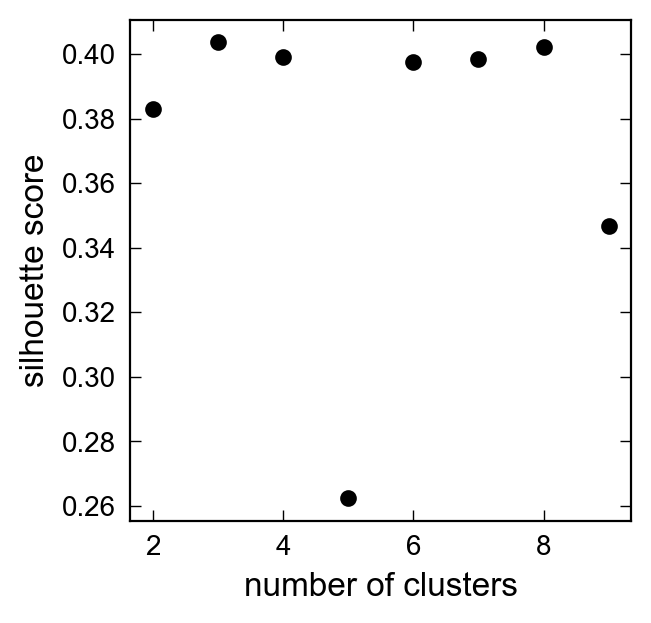

In [80]:
# Set number of clusters
fig, axs = plt.subplots(1,1, figsize=(4, 3.0), sharex='row', sharey=False,layout='constrained')

# Scale and center data for clustering
cluster_vars = ['Cysteine','Methionine', 'Histidine', 'Isoleucine', 'Arginine', 'Valine',
                'Tyrosine', 'Leucine', 'Serine', 'Tryptophan', 'Proline', 'Glutamine']
# ['Alanine', 'Arginine', 'Asparagine',
#        'AsparticAcid','GlutamicAcid', 'Glutamine', 'Glycine', # removed cysteine
#        'Histidine', 'Isoleucine', 'Leucine', 'Lysine', 'Methionine',
#        'Phenylalanine', 'Proline', 'Serine', 'Threonine', 'Tryptophan',
#        'Tyrosine', 'Valine']

cluster_input = amino_dropout_abundance_data[cluster_vars].sub(amino_dropout_abundance_data['day2_log10_abundance'], axis=0)
mask = np.sum(~np.isnan(cluster_input) & ~np.isinf(cluster_input), axis = 1) == len(cluster_vars)
scaler = StandardScaler()
scaler.fit(cluster_input[cluster_vars].values[mask])
# do PCA
pca = PCA(n_components=len(cluster_vars))
pca.fit(scaler.transform(cluster_input[cluster_vars].values[mask]))
print(pca.explained_variance_ratio_)
# dataset for clustering
for_clustering = PCA(n_components=3).fit_transform(scaler.transform(cluster_input[cluster_vars].values[mask]))

# compute scores
for k in np.arange(2,10):
    clustering_object = KMeans(n_clusters=k, n_init = 10, random_state=0)
    score = silhouette_score(for_clustering, clustering_object.fit_predict(for_clustering))
    axs.scatter(k,score, color = 'black')

axs.set_xlabel('number of clusters', fontsize = 12)
axs.set_ylabel('silhouette score', fontsize = 12)
axs.set_box_aspect(1)
axs.minorticks_off()
axs.tick_params(axis='both', which='major', labelsize=10)

#plt.savefig('_figs/figSI_'+comment+'-cluster_silhouette_scores'+'.pdf', format="pdf", transparent=True, dpi=300)

/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/pandas/core/internals/blocks.py:393: RuntimeWarning: divide by zero encountered in log10
  result = func(self.values, **kwargs)


[0.40675176 0.16873957 0.09056361 0.07463817 0.06354513 0.05868282
 0.0498634  0.03149407 0.02363952 0.00972224 0.00774851 0.00577371
 0.00405368 0.0019321  0.00136288 0.00086912 0.0006197 ]


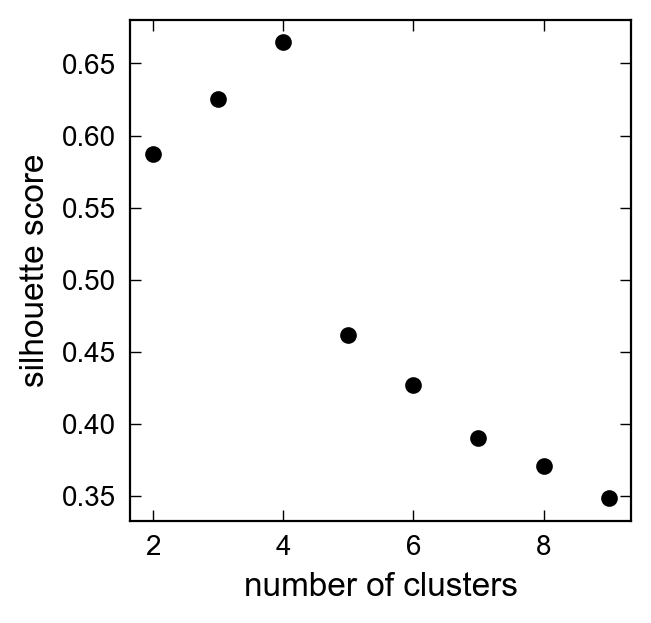

In [21]:
# Set number of clusters
fig, axs = plt.subplots(1,1, figsize=(4, 3.0), sharex='row', sharey=False,layout='constrained')

# Scale and center data for clustering
cluster_vars = ['H1-19','H1-38','H1-24','H1-26','H1-27','H1-09','H1-16',
            'H1-25',
            'H1-37','H1-39','H1-33','H1-34',
            'H1-41','H1-14','H1-08',
            'H1-28',
            'H1-23']

cluster_input = np.log10(cross_reactivity_data[cluster_vars].div(cross_reactivity_data['GF'], axis=0)).replace([-np.inf], 0.0)
mask = np.sum(~np.isnan(cluster_input) & ~np.isinf(cluster_input), axis = 1) == len(cluster_vars)
scaler = StandardScaler()
scaler.fit(cluster_input[cluster_vars].values[mask])
# do PCA
pca = PCA(n_components=len(cluster_vars))
pca.fit(scaler.transform(cluster_input[cluster_vars].values[mask]))
print(pca.explained_variance_ratio_)
# dataset for clustering
for_clustering = PCA(n_components=3).fit_transform(scaler.transform(cluster_input[cluster_vars].values[mask]))

# compute scores
for k in np.arange(2,10):
    clustering_object = KMeans(n_clusters=k, n_init = 10, random_state=0)
    score = silhouette_score(for_clustering, clustering_object.fit_predict(for_clustering))
    axs.scatter(k,score, color = 'black')

axs.set_xlabel('number of clusters', fontsize = 12)
axs.set_ylabel('silhouette score', fontsize = 12)
axs.set_box_aspect(1)
axs.minorticks_off()
axs.tick_params(axis='both', which='major', labelsize=10)

#plt.savefig('_figs/figSI_'+comment+'-cluster_silhouette_scores'+'.pdf', format="pdf", transparent=True, dpi=300)

[0.43407171 0.34628146 0.21964683]


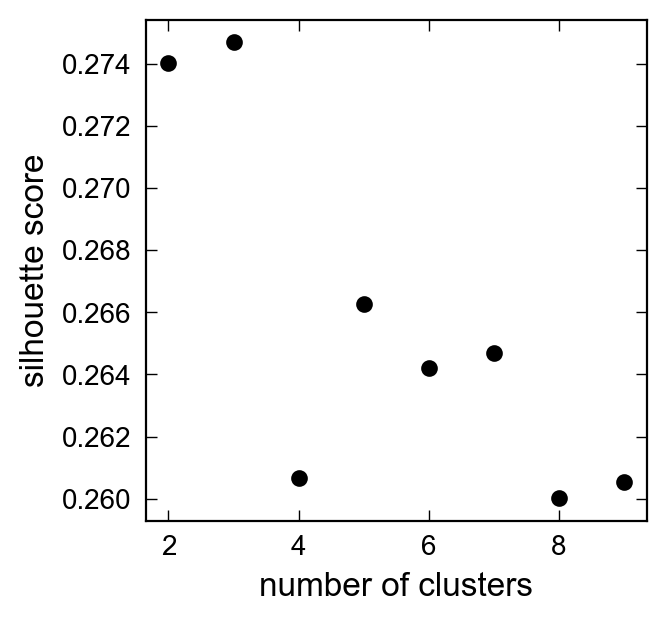

In [22]:
# Set number of clusters
fig, axs = plt.subplots(1,1, figsize=(4, 3.0), sharex='row', sharey=False,layout='constrained')

# Scale and center data for clustering
cluster_vars = ['hCom1d_pTreg_Average', 'hCom1d_Th17_Average', 'hCom1d_FR4_Th_Average']

cluster_input = coverage_data[cluster_vars].values - coverage_data[['GF_pTreg_Average','GF_Th17_Average', 'GF_FR4_Th_Average']].values
mask = np.sum(~np.isnan(cluster_input) & ~np.isinf(cluster_input), axis = 1) == len(cluster_vars)
scaler = StandardScaler()
scaler.fit(cluster_input[mask])
# do PCA
pca = PCA(n_components=len(cluster_vars))
pca.fit(scaler.transform(cluster_input[mask]))
print(pca.explained_variance_ratio_)
# dataset for clustering
for_clustering = scaler.transform(cluster_input[mask])

# compute scores
for k in np.arange(2,10):
    clustering_object = KMeans(n_clusters=k, n_init = 10, random_state=0)
    score = silhouette_score(for_clustering, clustering_object.fit_predict(for_clustering))
    axs.scatter(k,score, color = 'black')

axs.set_xlabel('number of clusters', fontsize = 12)
axs.set_ylabel('silhouette score', fontsize = 12)
axs.set_box_aspect(1)
axs.minorticks_off()
axs.tick_params(axis='both', which='major', labelsize=10)

#plt.savefig('_figs/figSI_'+comment+'-cluster_silhouette_scores'+'.pdf', format="pdf", transparent=True, dpi=300)

In [81]:
df_list = [strain_dropout_abundance_data, amino_dropout_abundance_data,cross_reactivity_data]
cluster_vars_list = [['drop_Ch_abundance','drop_Cs_abundance'],
                     ['Cysteine','Methionine', 'Histidine', 'Isoleucine', 'Arginine', 'Valine',
                'Tyrosine', 'Leucine', 'Serine', 'Tryptophan', 'Proline', 'Glutamine'],
                     ['H1-19','H1-38','H1-24','H1-26','H1-27','H1-09','H1-16',
                      'H1-25',
                      'H1-37','H1-39','H1-33','H1-34',
                      'H1-41','H1-14','H1-08',
                      'H1-28',
                      'H1-23']]
reference_vars_list = ['week3_cecum_abundance', 'day2_log10_abundance','GF']
label_list = ['strain_drop','amino_drop','cross_reactivity']
cluster_num_list = [4,3,5]
pca_num_list = [2,3,4]
feces_abundance_w_clusters = feces_abundance_data.loc[feces_abundance_data.strain_id.notna()]


for i,df in enumerate(df_list):
    if i == 0:
        scaler = RobustScaler()
        cluster_input = df[cluster_vars_list[i]].div(df[reference_vars_list[i]], axis=0)
        mask = np.sum(~np.isnan(cluster_input) & ~np.isinf(np.log10(cluster_input)), axis = 1) == len(cluster_vars_list[i])
        scaler.fit(np.log10(cluster_input[cluster_vars_list[i]].values[mask]))
        for_clustering = scaler.transform(np.log10(cluster_input[cluster_vars_list[i]].values[mask]))
    elif i == 1:
        scaler = StandardScaler()
        cluster_input = df[cluster_vars_list[i]].sub(df[reference_vars_list[i]], axis=0)
        mask = np.sum(~np.isnan(cluster_input) & ~np.isinf(cluster_input), axis = 1) == len(cluster_vars_list[i])
        scaler.fit(cluster_input[cluster_vars_list[i]].values[mask])
        for_clustering = PCA(n_components=pca_num_list[i]).fit_transform(scaler.transform(cluster_input[cluster_vars_list[i]].values[mask]))
    else:
        scaler = StandardScaler()
        cluster_input = np.log10(df[cluster_vars_list[i]].div(df[reference_vars_list[i]], axis=0)).replace([-np.inf], 0.0)
        mask = np.sum(~np.isnan(cluster_input) & ~np.isinf(cluster_input), axis = 1) == len(cluster_vars_list[i])
        scaler.fit(cluster_input[cluster_vars_list[i]].values[mask])
        for_clustering = PCA(n_components=pca_num_list[i]).fit_transform(scaler.transform(cluster_input[cluster_vars_list[i]].values[mask]))

    cluster_input['strain_id'] = df['strain_id'] 
    clustering_object = KMeans(n_clusters=cluster_num_list[i], n_init = 10, random_state=0)
    clustering = clustering_object.fit(for_clustering)
    cluster_input.loc[mask,label_list[i]+'_cluster'] = clustering.labels_
    feces_abundance_w_clusters = feces_abundance_w_clusters.merge(cluster_input.loc[cluster_input.strain_id.notna(),['strain_id', label_list[i]+'_cluster'] + (cluster_vars_list[i] if i == 0 else [])], 
                               how = 'left', on = 'strain_id', validate = 'one_to_one')

/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/pandas/core/internals/blocks.py:393: RuntimeWarning: divide by zero encountered in log10
  result = func(self.values, **kwargs)
/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/pandas/core/internals/blocks.py:393: RuntimeWarning: divide by zero encountered in log10
  result = func(self.values, **kwargs)


/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_14886/1130932420.py:15: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


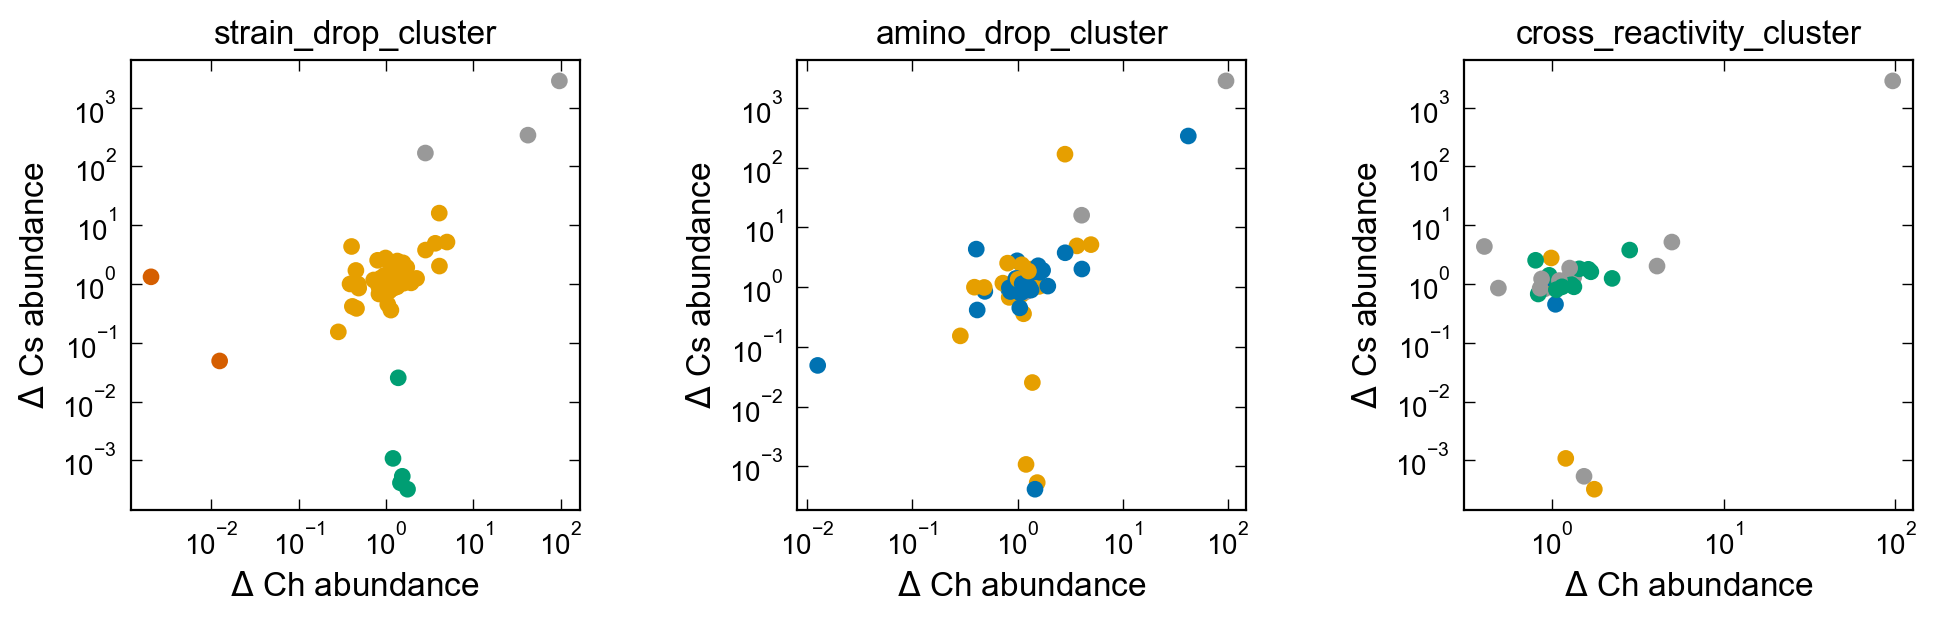

In [82]:
# Plot figures
plot_variables = ['drop_Ch_abundance','drop_Cs_abundance']
cluster_variables= ['strain_drop_cluster','amino_drop_cluster','cross_reactivity_cluster']

fig, axs = plt.subplots(1, 3, figsize=(10.0, 3.0), sharex = False, constrained_layout=True)

for i, ax in enumerate(axs):

    ax.scatter(feces_abundance_w_clusters[plot_variables[0]], 
               feces_abundance_w_clusters[plot_variables[1]],
                c = feces_abundance_w_clusters[cluster_variables[i]],
              cmap = custom_cmap_discrete)

for j, ax in enumerate(axs.flat):
    ax.legend()
    ax.semilogx()
    ax.semilogy()
    ax.set_xlabel(r'$\Delta$ Ch abundance', fontsize = 12)
    ax.set_ylabel(r'$\Delta$ Cs abundance', fontsize = 12)
    ax.set_title(cluster_variables[j], fontsize = 12)   
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

# plt.savefig('_figs/fig5_'+comment+'-perf_perturb_design'+'.pdf', format="pdf", transparent=True, dpi=300)

In [88]:
cluster_input[['strain_id', 'cross_reactivity_cluster']]

,strain_id,cross_reactivity_cluster
0,clostridium bolteae atcc baa-613,1.0
1,hungatella hathewayi dsm 13479,1.0
2,coprococcus eutactus atcc 27759,1.0
3,dorea longicatena dsm 13814,1.0
4,tyzzerella nexilis dsm 1787,1.0
5,dorea formicigenerans atcc 27755,1.0
6,eubacterium rectale atcc 33656,1.0
7,blautia hansenii dsm 20583,1.0
8,ruminococcus torques atcc 27756,1.0
9,clostridium sp. l2-50,1.0


In [85]:
# feces_abundance_w_clusters[['strain_id','strain_drop_cluster','amino_drop_cluster','cross_reactivity_cluster']]

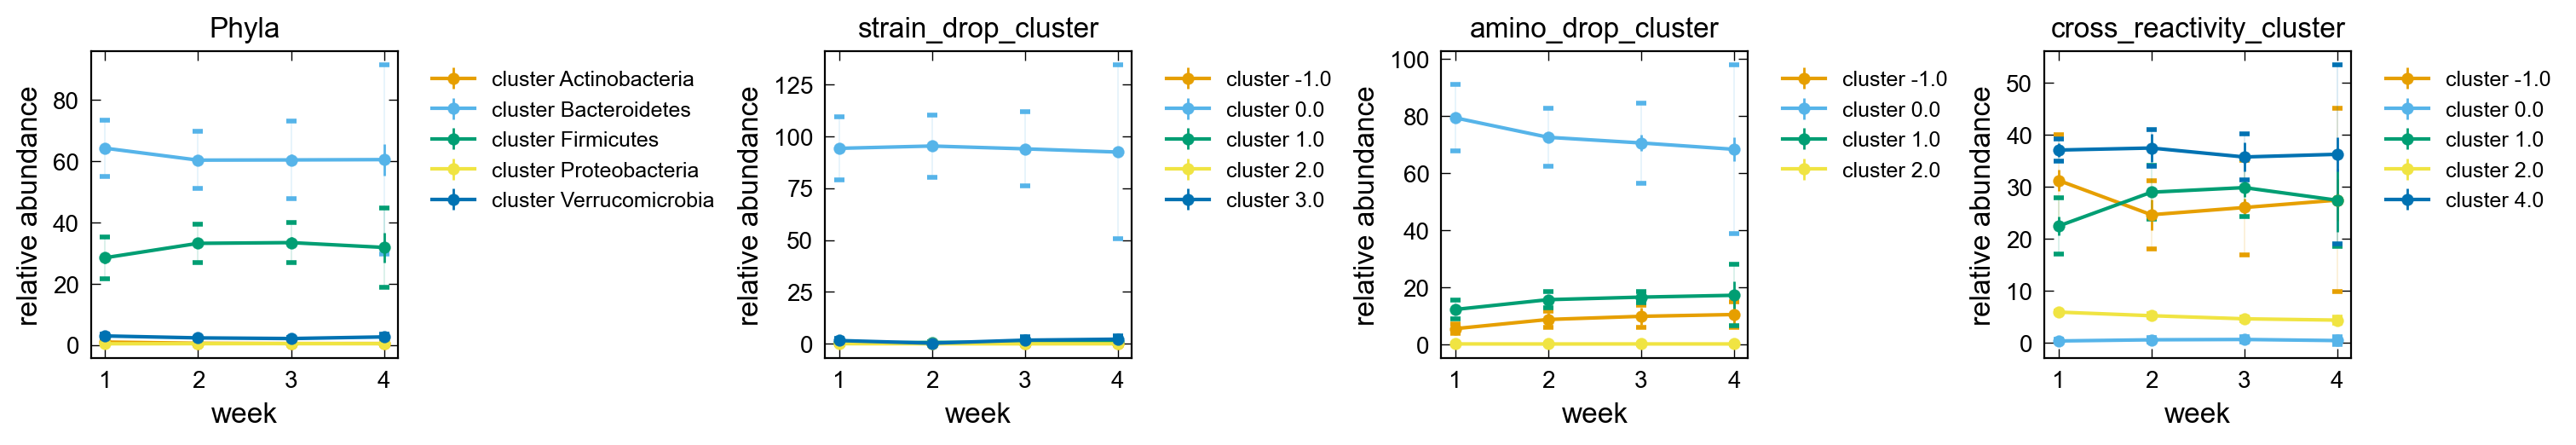

In [86]:
# Plot figures
plot_variables = ['GF_Th17_Average', 'hCom1d_Th17_Average']
cluster_variables= ['Phyla','strain_drop_cluster','amino_drop_cluster','cross_reactivity_cluster']
var_list = ['Batch1_week1_m1',
       'Batch1_week1_m2', 'Batch1_week1_m3', 'Batch1_week1_m4',
       'Batch1_week1_m5', 'Batch1_week2_m1', 'Batch1_week2_m2',
       'Batch1_week2_m3', 'Batch1_week2_m4', 'Batch1_week2_m5',
       'Batch1_week3_m1', 'Batch1_week3_m2', 'Batch1_week3_m3',
       'Batch1_week3_m4', 'Batch1_week3_m5', 'Batch1_week4_m1',
       'Batch1_week4_m2', 'Batch1_week4_m3', 'Batch1_week4_m4',
       'Batch1_week4_m5', 'Batch2_week4_m1', 'Batch2_week4_m2',
       'Batch2_week4_m3', 'Batch3_week4_m1', 'Batch3_week4_m2',
       'Batch3_week4_m3', 'Batch3_week4_m4', 'Batch3_week4_m5',
        'wk1_std_abundance', 'wk2_std_abundance','wk3_std_abundance','wk4_std_abundance']

fig, axs = plt.subplots(1, 4, figsize=(15.0, 3.0), sharex = False, constrained_layout=True)

for i, ax in enumerate(axs):
    data = feces_abundance_w_clusters.fillna(-1)[var_list + [cluster_variables[i]]].groupby(cluster_variables[i], as_index = False).sum()
    null_model_std_data = data[[cluster_variables[i], 'wk1_std_abundance', 'wk2_std_abundance','wk3_std_abundance','wk4_std_abundance']].values
    
    # Compute mean abundance
    data.loc[:, 'wk1_mean_abundance'] = np.mean(data[['Batch1_week1_m1','Batch1_week1_m2', 'Batch1_week1_m3', 
                                                                                 'Batch1_week1_m4','Batch1_week1_m5']], axis = 1)
    data.loc[:, 'wk2_mean_abundance'] = np.mean(data[['Batch1_week2_m1', 'Batch1_week2_m2','Batch1_week2_m3', 
                                                                                 'Batch1_week2_m4', 'Batch1_week2_m5']], axis = 1)
    data.loc[:, 'wk3_mean_abundance'] = np.mean(data[['Batch1_week3_m1', 'Batch1_week3_m2', 'Batch1_week3_m3', 
                                                                                 'Batch1_week3_m4', 'Batch1_week3_m5']], axis = 1)
    data.loc[:, 'wk4_mean_abundance'] = np.mean(data[['Batch1_week4_m1','Batch1_week4_m2', 'Batch1_week4_m3', 'Batch1_week4_m4',
                                                                                 'Batch1_week4_m5', 'Batch2_week4_m1', 'Batch2_week4_m2',
                                                                                 'Batch2_week4_m3', 'Batch3_week4_m1', 'Batch3_week4_m2',
                                                                                 'Batch3_week4_m3', 'Batch3_week4_m4', 'Batch3_week4_m5']], axis = 1)
    
    # Compute standard deviation of abundance
    data.loc[:, 'wk1_std_abundance'] = np.std(data[['Batch1_week1_m1','Batch1_week1_m2', 'Batch1_week1_m3', 
                                                                                 'Batch1_week1_m4','Batch1_week1_m5']], axis = 1)
    data.loc[:, 'wk2_std_abundance'] = np.std(data[['Batch1_week2_m1', 'Batch1_week2_m2','Batch1_week2_m3', 
                                                                                 'Batch1_week2_m4', 'Batch1_week2_m5']], axis = 1)
    data.loc[:, 'wk3_std_abundance'] = np.std(data[['Batch1_week3_m1', 'Batch1_week3_m2', 'Batch1_week3_m3', 
                                                                                 'Batch1_week3_m4', 'Batch1_week3_m5']], axis = 1)
    data.loc[:, 'wk4_std_abundance'] = np.std(data[['Batch1_week4_m1','Batch1_week4_m2', 'Batch1_week4_m3', 'Batch1_week4_m4',
                                                                                 'Batch1_week4_m5', 'Batch2_week4_m1', 'Batch2_week4_m2',
                                                                                 'Batch2_week4_m3', 'Batch3_week4_m1', 'Batch3_week4_m2',
                                                                                 'Batch3_week4_m3', 'Batch3_week4_m4', 'Batch3_week4_m5']], axis = 1)

    mean_data = data[[cluster_variables[i], 'wk1_mean_abundance', 'wk2_mean_abundance','wk3_mean_abundance','wk4_mean_abundance']].values
    std_data = data[[cluster_variables[i], 'wk1_std_abundance', 'wk2_std_abundance','wk3_std_abundance','wk4_std_abundance']].values
    x_data = np.array([1, 2, 3, 4])
    for k, y in enumerate(mean_data):
        ax.errorbar(x_data, y[1:],
            yerr = null_model_std_data[k,1:],elinewidth = 0.1,linewidth = 0.1,fmt = '-', color = ito_colors[k], capsize = 2.0, capthick = 2.0)
        ax.errorbar(x_data, y[1:],
                    yerr = std_data[k,1:],elinewidth = 1.0,linewidth = 1.5,fmt = '-o', color = ito_colors[k], label = 'cluster '+str(y[0]))

for j, ax in enumerate(axs.flat):
    ax.legend(bbox_to_anchor=(1.05, 1.0), fontsize=9, framealpha=0)
    # ax.semilogx()
    # ax.semilogy()
    ax.set_xlabel('week', fontsize = 12)
    ax.set_ylabel(r'relative abundance', fontsize = 12)
    ax.set_title(cluster_variables[j], fontsize = 12)   
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

# plt.savefig('_figs/fig5_'+comment+'-perf_perturb_design'+'.pdf', format="pdf", transparent=True, dpi=300)